# 4. RWKV-4 od zera w PyTorch

**Teoria do tego notebooka:** [`04_rwkv.md`](04_rwkv.md) (warto przeczytać najpierw sekcje 4.4–4.9).

Implementujemy RWKV-4, czyli wersję z paperu
[*RWKV: Reinventing RNNs for the Transformer Era*](https://arxiv.org/abs/2305.13048), wiernie względem
oficjalnego kodu (`RWKV-LM/RWKV-v4`), ale czytelnie i bez kernela CUDA.

Plan:

- **Część A: operator WKV**, serce RWKV, policzony na 5 sposobów (pętla z równania, RNN naiwny, RNN stabilny,
  w pełni równolegle jak attention, blokami). Sprawdzamy, że to jedno i to samo, i mierzymy szybkość.
- **Część B: cały model RWKV-4** (token shift, time-mixing, channel-mixing) z dwoma trybami: GPT i RNN.
- **Część C: trening** na "Panu Tadeuszu" i porównanie z RNN, LSTM i Transformerem.
- **Część D: wydajność inferencji**: stały koszt tokenu i stała pamięć vs KV cache Transformera.
- **Część E: czego model się nauczył** (zaniki w warstwach, "uwaga" RWKV na tekście).
- **Część F: zadanie pamięciowe.**

In [1]:
import gc
import math
import time

import matplotlib.pyplot as plt
import torch
import torch.nn as nn

from common import (MEMORY_VOCAB, count_params, lm_loss, load_results, plot_memory, prepare_data,
                    run_memory_experiment, sample_from_logits, save_results, set_seed, time_fn,
                    train, TrainConfig)

plt.rcParams["figure.dpi"] = 110
tok, train_data, val_data = prepare_data()

---
# Część A: operator WKV

Dla każdego kanału osobno (wszystkie operacje są element po elemencie po wymiarze kanałów $C$):

$$
wkv_t = \frac{\sum_{i<t} e^{-(t-1-i)w + k_i}\, v_i \;+\; e^{u + k_t}\, v_t}{\sum_{i<t} e^{-(t-1-i)w + k_i} \;+\; e^{u + k_t}}
$$

- $w > 0$: szybkość zaniku (wektor długości $C$), w modelu $w = e^{\text{time\_decay}}$,
- $u$: bonus dla bieżącego tokenu (wektor długości $C$, `time_first`),
- $k, v$: tensory `(B, T, C)`.

### A1. Wprost z równania (pętle, tylko do sprawdzania)

In [2]:
def wkv_reference(w, u, k, v):
    B, T, C = k.shape
    out = torch.zeros_like(v)
    for b in range(B):
        for t in range(T):
            num = torch.exp(u + k[b, t]) * v[b, t]
            den = torch.exp(u + k[b, t])
            for i in range(t):
                weight = torch.exp(-(t - 1 - i) * w + k[b, i])
                num = num + weight * v[b, i]
                den = den + weight
            out[b, t] = num / den
    return out

### A2. Tryb RNN, wersja naiwna (paper, Appendix D, równania 19–22)

$$
a_t = e^{-w} a_{t-1} + e^{k_t} v_t, \qquad b_t = e^{-w} b_{t-1} + e^{k_t}, \qquad
wkv_t = \frac{a_{t-1} + e^{u+k_t} v_t}{b_{t-1} + e^{u+k_t}}
$$

In [3]:
def wkv_rnn_naive(w, u, k, v):
    B, T, C = k.shape
    a, b = k.new_zeros(B, C), k.new_zeros(B, C)
    outs = []
    for k_t, v_t in zip(k.unbind(1), v.unbind(1)):
        e_uk = torch.exp(u + k_t)
        outs.append((a + e_uk * v_t) / (b + e_uk))
        a = torch.exp(-w) * a + torch.exp(k_t) * v_t
        b = torch.exp(-w) * b + torch.exp(k_t)
    return torch.stack(outs, dim=1)

### A3. Tryb RNN, wersja stabilna (jak w oficjalnym kernelu RWKV-4)

Stan to $(a', b', p)$ z $a = a' e^{p}$, $b = b' e^{p}$, gdzie $p$ to bieżący największy wykładnik.
Każdy $e^{(\cdot)}$ ma argument $\le 0$, więc nic nie wybucha (to ten sam trik co w stabilnym softmaksie).
Stan początkowy: $a' = 0$, $b' = 1$, $p = -10^{38}$ (czyli "pusta pamięć", bo $e^{p} = 0$).

In [4]:
def empty_wkv_state(batch_size, channels):
    return torch.zeros(batch_size, channels), torch.ones(batch_size, channels), torch.full((batch_size, channels), -1e38)


def wkv_step(w, u, k_t, v_t, state):
    """Jeden krok tokenu: (B, C) -> wyjście (B, C) i nowy stan (a', b', p)."""
    aa, bb, pp = state
    ww = u + k_t                                   # wykładnik bieżącego tokenu (z bonusem)
    q = torch.maximum(pp, ww)
    e1, e2 = torch.exp(pp - q), torch.exp(ww - q)
    out = (e1 * aa + e2 * v_t) / (e1 * bb + e2)
    ww = pp - w                                    # przeszłość zanika o jeden krok
    q = torch.maximum(ww, k_t)
    e1, e2 = torch.exp(ww - q), torch.exp(k_t - q)
    return out, (e1 * aa + e2 * v_t, e1 * bb + e2, q)


def wkv_rnn(w, u, k, v, state=None):
    B, T, C = k.shape
    state = empty_wkv_state(B, C) if state is None else state
    outs = []
    for k_t, v_t in zip(k.unbind(1), v.unbind(1)):
        out, state = wkv_step(w, u, k_t, v_t, state)
        outs.append(out)
    return torch.stack(outs, dim=1), state

### A4. W pełni równolegle, jak attention

$wkv_t = \sum_i \operatorname{softmax}_i(k_i + \text{bias}_{t,i})\, v_i$, gdzie bias to kara za odległość:

$$
\text{bias}_{t,i} = \begin{cases} -(t-1-i)\,w & i < t \\ u & i = t \\ -\infty & i > t \end{cases}
$$

To jest "maska przyczynowa + ALiBi" z rozdziału 3, tylko osobna dla każdego kanału i **bez zapytań** $q$.

In [5]:
def decay_bias(w, u, targets, sources):
    """(C, len(targets), len(sources)): bias[c, t, i] = -(t-1-i)·w[c] dla i<t, u[c] dla i=t, -inf dla i>t."""
    t = targets.to(w.dtype)[:, None]
    i = sources.to(w.dtype)[None, :]
    bias = torch.where(i < t, -(t - 1 - i) * w[:, None, None], float("-inf"))
    return torch.where(i == t, u[:, None, None], bias)


def wkv_parallel(w, u, k, v):
    T = k.shape[1]
    k, v = k.transpose(1, 2), v.transpose(1, 2)                          # (B, C, T)
    scores = k[:, :, None, :] + decay_bias(w, u, torch.arange(T), torch.arange(T))   # (B, C, T, T)
    return (scores.softmax(dim=-1) @ v[..., None]).squeeze(-1).transpose(1, 2)

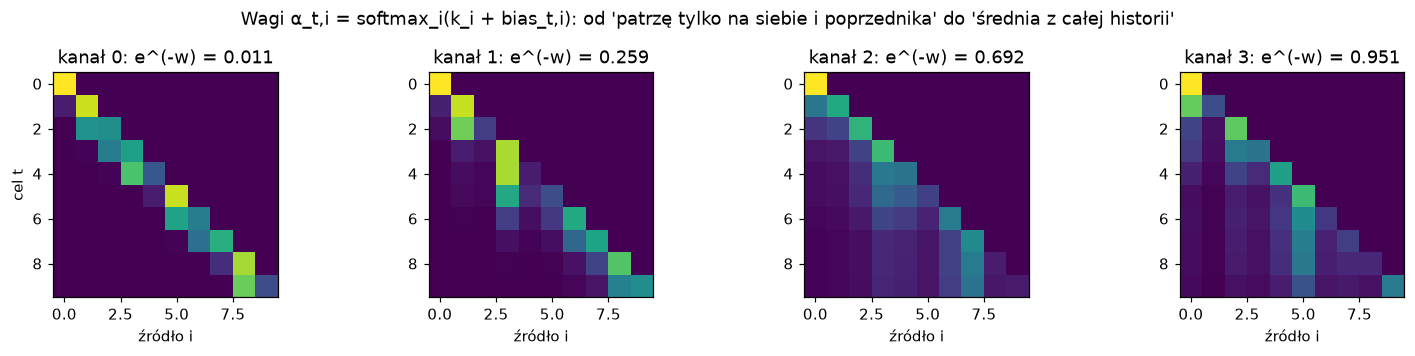

In [6]:
C = 4
w_demo = torch.exp(torch.tensor([1.5, 0.3, -1.0, -3.0]))
u_demo = torch.full((C,), 0.5)
bias = decay_bias(w_demo, u_demo, torch.arange(10), torch.arange(10))
k_demo = torch.randn(1, 10, C, generator=torch.Generator().manual_seed(0))
alpha = (k_demo.transpose(1, 2)[:, :, None, :] + bias).softmax(-1)[0]

fig, axes = plt.subplots(1, C, figsize=(14, 3.2))
for c in range(C):
    axes[c].imshow(alpha[c], cmap="viridis", vmin=0, vmax=1)
    axes[c].set_title(f"kanał {c}: e^(-w) = {math.exp(-w_demo[c]):.3f}")
    axes[c].set_xlabel("źródło i")
axes[0].set_ylabel("cel t")
plt.suptitle("Wagi α_t,i = softmax_i(k_i + bias_t,i): od 'patrzę tylko na siebie i poprzednika' do 'średnia z całej historii'")
plt.tight_layout()
plt.show()

### A5. Blokami (*chunked*): równolegle w bloku, rekurencyjnie między blokami

Dzielimy sekwencję na bloki długości $L$. Trik: stan sprzed bloku $(a, b)$ jest jak **jeden wirtualny token**
na pozycji $-1$, z "kluczem" $\log b$ i "wartością" $a/b$ (średnia ważona całej przeszłości).
Dla celu $t$ jego bias to $-(t-1-(-1))\,w = -t\,w$, czyli ta sama formuła co dla zwykłych tokenów.
Dodajemy też jeden wiersz "celu" na pozycji $t = L$ (tuż za blokiem, bez bonusu): jego softmax to dokładnie
nowy stan na koniec bloku. Cały blok to więc **jeden softmax po macierzy $(L+1) \times (L+1)$**.

![schemat](assets/04_chunki.png)

In [7]:
def wkv_chunked(w, u, k, v, state=None, chunk_len=16):
    B, T, C = k.shape
    k, v = k.transpose(1, 2), v.transpose(1, 2)                          # (B, C, T)
    aa, bb, pp = empty_wkv_state(B, C) if state is None else state
    mean, log_weight = aa / bb, pp + torch.log(bb)                      # stan jako (średnia wartość, log wagi)
    outs, biases = [], {}
    for k_c, v_c in zip(k.split(chunk_len, dim=-1), v.split(chunk_len, dim=-1)):
        L = k_c.shape[-1]
        if L not in biases:
            biases[L] = decay_bias(w, u, torch.arange(L + 1), torch.arange(-1, L))   # (C, L+1, L+1)
        keys = torch.cat([log_weight[..., None], k_c], dim=-1)          # (B, C, 1+L), pozycja -1 = stan
        vals = torch.cat([mean[..., None], v_c], dim=-1)
        scores = keys[:, :, None, :] + biases[L]                         # (B, C, L+1, 1+L)
        mix = (scores.softmax(dim=-1) @ vals[..., None]).squeeze(-1)     # (B, C, L+1)
        outs.append(mix[..., :L])
        mean, log_weight = mix[..., L], torch.logsumexp(scores[..., L, :], dim=-1)
    out = torch.cat(outs, dim=-1).transpose(1, 2)
    return out, (mean.contiguous(), torch.ones_like(mean), log_weight)

### A6. Czy to wszystko liczy to samo?

In [8]:
set_seed(0)
B, T, C = 2, 23, 5
w = torch.exp(torch.randn(C))
u = torch.randn(C)
k, v = torch.randn(B, T, C), torch.randn(B, T, C)
ref = wkv_reference(w.double(), u.double(), k.double(), v.double()).float()

candidates = {
    "RNN naiwny": wkv_rnn_naive(w, u, k, v),
    "RNN stabilny": wkv_rnn(w, u, k, v)[0],
    "równolegle (T×T)": wkv_parallel(w, u, k, v),
    "blokami, L=1": wkv_chunked(w, u, k, v, chunk_len=1)[0],
    "blokami, L=4": wkv_chunked(w, u, k, v, chunk_len=4)[0],
    "blokami, L=16": wkv_chunked(w, u, k, v, chunk_len=16)[0],
}
for name, out in candidates.items():
    print(f"{name:18s} max |różnica| = {(out - ref).abs().max().item():.1e}")

out1, st = wkv_chunked(w, u, k[:, :10], v[:, :10], chunk_len=4)
out2, _ = wkv_rnn(w, u, k[:, 10:], v[:, 10:], state=st)
print("\nblokami do t=10, potem tryb RNN ze stanem:", f"{(torch.cat([out1, out2], 1) - ref).abs().max().item():.1e}")

RNN naiwny         max |różnica| = 2.4e-07
RNN stabilny       max |różnica| = 2.4e-07
równolegle (T×T)   max |różnica| = 2.4e-07
blokami, L=1       max |różnica| = 2.4e-07
blokami, L=4       max |różnica| = 2.4e-07
blokami, L=16      max |różnica| = 2.4e-07

blokami do t=10, potem tryb RNN ze stanem: 2.4e-07


Wszystkie wersje zgadzają się co do błędu zaokrągleń float32. Stan z wersji blokowej można przekazać do
wersji RNN i kontynuować: dokładnie tak RWKV przechodzi z trybu treningowego do generowania.

**A teraz duże klucze**, np. $k = 100$ (w fp16 problem zaczyna się już przy $k > 11$):

In [9]:
k_big = torch.full((1, 6, C), 100.0)
v_small = torch.randn(1, 6, C)
print("RNN naiwny: ", wkv_rnn_naive(w, u, k_big, v_small)[0, :3, 0])
print("RNN stabilny:", wkv_rnn(w, u, k_big, v_small)[0][0, :3, 0])
print("blokami:     ", wkv_chunked(w, u, k_big, v_small)[0][0, :3, 0])

RNN naiwny:  tensor([nan, nan, nan])
RNN stabilny: tensor([-0.5461, -0.4320, -0.2261])
blokami:      tensor([-0.5461, -0.4320, -0.2261])


$e^{100}$ nie mieści się we float32, więc wersja naiwna daje `inf/inf = nan`. Wersje stabilne liczą poprawnie.
RWKV-2/3 ratowały się obcinaniem `k ≤ 60` i dodawaniem epsilonu do mianownika. RWKV-4 rozwiązał to porządnie.

### A7. Szybkość na CPU

Mierzymy przebieg w przód + w tył (jak w treningu) dla `B=8, C=128` i rosnącego $T$.

In [10]:
def bench_wkv(fn, T, B=8, C=128, repeats=3):
    w, u = torch.exp(torch.randn(C)), torch.randn(C)
    k = torch.randn(B, T, C, requires_grad=True)
    v = torch.randn(B, T, C, requires_grad=True)
    return time_fn(lambda: fn(w, u, k, v).sum().backward(), repeats=repeats, warmup=1) * 1000


wkv_speed = {"T": [128, 256, 512, 1024, 2048], "rnn": [], "parallel": [], "chunked16": []}
for T in wkv_speed["T"]:
    wkv_speed["rnn"].append(bench_wkv(lambda *a: wkv_rnn(*a)[0], T))
    wkv_speed["parallel"].append(bench_wkv(wkv_parallel, T) if T <= 1024 else float("nan"))
    wkv_speed["chunked16"].append(bench_wkv(lambda *a: wkv_chunked(*a, chunk_len=16)[0], T))
    print(f"T={T:5d}: RNN {wkv_speed['rnn'][-1]:7.1f} ms | równolegle {wkv_speed['parallel'][-1]:7.1f} ms"
          f" | blokami(16) {wkv_speed['chunked16'][-1]:7.1f} ms")

chunk_speed = {"L": [1, 2, 4, 8, 16, 32, 64, 128, 512], "ms": []}
for L in chunk_speed["L"]:
    chunk_speed["ms"].append(bench_wkv(lambda *a: wkv_chunked(*a, chunk_len=L)[0], 512))

T=  128: RNN    28.0 ms | równolegle    89.6 ms | blokami(16)     8.0 ms


T=  256: RNN    49.4 ms | równolegle   353.3 ms | blokami(16)    19.8 ms


T=  512: RNN   108.0 ms | równolegle  1449.5 ms | blokami(16)    41.5 ms


T= 1024: RNN   228.1 ms | równolegle 11644.6 ms | blokami(16)    92.5 ms


T= 2048: RNN   500.0 ms | równolegle     nan ms | blokami(16)   175.0 ms


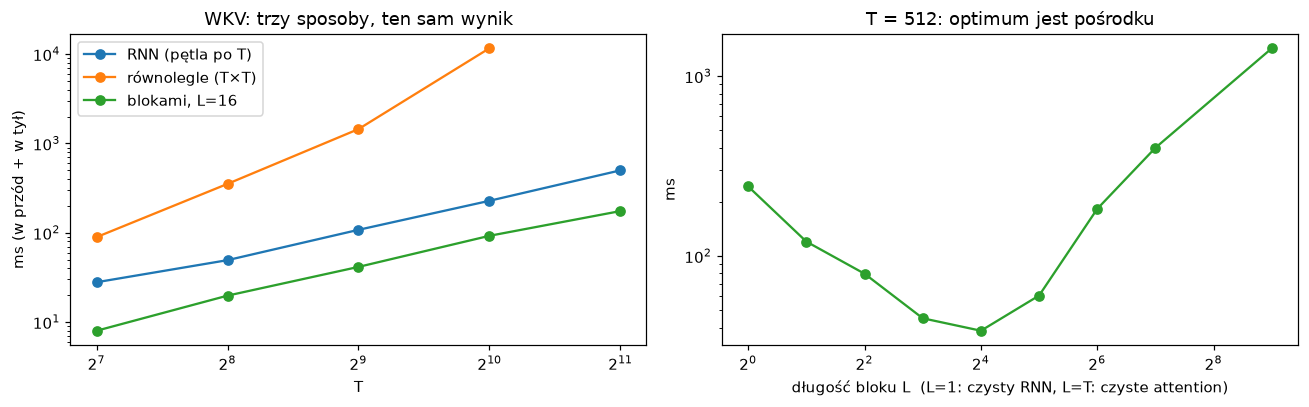

PosixPath('/home/womackow/CODE_SPACE/agh/sem2/UMISI-sem2-NN-Arch/RWKV/results/04_wkv_speed.json')

In [11]:
fig, axes = plt.subplots(1, 2, figsize=(12, 3.8))
for key, label in [("rnn", "RNN (pętla po T)"), ("parallel", "równolegle (T×T)"), ("chunked16", "blokami, L=16")]:
    axes[0].plot(wkv_speed["T"], wkv_speed[key], "o-", label=label)
axes[0].set_xscale("log", base=2)
axes[0].set_yscale("log")
axes[0].set_xlabel("T")
axes[0].set_ylabel("ms (w przód + w tył)")
axes[0].set_title("WKV: trzy sposoby, ten sam wynik")
axes[0].legend()
axes[1].plot(chunk_speed["L"], chunk_speed["ms"], "o-", color="C2")
axes[1].set_xscale("log", base=2)
axes[1].set_yscale("log")
axes[1].set_xlabel("długość bloku L  (L=1: czysty RNN, L=T: czyste attention)")
axes[1].set_ylabel("ms")
axes[1].set_title("T = 512: optimum jest pośrodku")
plt.tight_layout()
plt.show()
save_results("04_wkv_speed", {"by_T": wkv_speed, "by_chunk": chunk_speed})

- **RNN**: $T$ kroków po kolei, każdy tani. Czas rośnie liniowo.
- **Równolegle**: zero pętli, ale macierz $T \times T$ na każdy kanał, więc czas i pamięć rosną kwadratowo.
- **Blokami**: tylko $T/L$ kroków sekwencyjnych i małe macierze. Najszybciej. Optymalne $L$ zależy od sprzętu
  (na GPU większe bloki, bo równoległość jest tańsza).

Oficjalny kernel CUDA RWKV-4 robi wariant "RNN": jeden wątek na parę (batch, kanał), pętla po czasie. Na GPU
to wystarcza, bo wątków jest $B \cdot C$ (dziesiątki tysięcy), a WKV ma ok. $d$ razy mniej obliczeń niż mnożenia
macierzy. Na CPU, bez dedykowanego kernela, WKV kosztuje u nas mniej więcej tyle co wszystkie mnożenia macierzy.

### A8. Dygresja: dlaczego liniową rekurencję w ogóle da się zrównoleglić?

Rekurencja $s_t = \lambda_t s_{t-1} + z_t$ to złożenie funkcji liniowych. Dwa kroki składają się w jeden:
$(\lambda_a, z_a) \circ (\lambda_b, z_b) = (\lambda_a \lambda_b,\ \lambda_b z_a + z_b)$, a to złożenie jest **łączne**.
Można więc liczyć "drzewem": po kroku 1 każdy element zna sumę 2 ostatnich, po kroku 2 sumę 4, potem 8...
Po $\log_2 T$ krokach (każdy na wszystkich pozycjach naraz) mamy wszystkie stany
(algorytm Hillisa–Steele'a; [Blelloch 1990](https://www.cs.cmu.edu/~guyb/papers/Ble93.pdf)).

Dla RNN z $h_t = \tanh(W h_{t-1} + x_t)$ takiego złożenia **nie ma**: złożenie dwóch kroków z tanh nie jest
funkcją tej samej, prostej postaci. Dlatego rekurencja nieliniowa jest z natury sekwencyjna.

In [12]:
def linear_scan_loop(lam, z):
    s, out = torch.zeros_like(z[..., 0]), []
    for t in range(z.shape[-1]):
        s = lam[..., t] * s + z[..., t]
        out.append(s)
    return torch.stack(out, dim=-1)


def linear_scan_parallel(lam, z):
    lam, z = lam.clone(), z.clone()
    step, n_steps = 1, 0
    while step < z.shape[-1]:
        z = torch.cat([z[..., :step], lam[..., step:] * z[..., :-step] + z[..., step:]], dim=-1)
        lam = torch.cat([lam[..., :step], lam[..., step:] * lam[..., :-step]], dim=-1)
        step, n_steps = step * 2, n_steps + 1
    return z, n_steps


lam = torch.rand(64, 4096) * 0.2 + 0.8
z = torch.randn(64, 4096)
seq_out = linear_scan_loop(lam, z)
par_out, n_steps = linear_scan_parallel(lam, z)
print(f"max różnica: {(seq_out - par_out).abs().max().item():.1e}")
print(f"pętla: 4096 kroków sekwencyjnych ({time_fn(lambda: linear_scan_loop(lam, z), 3) * 1000:.0f} ms)")
print(f"skan równoległy: {n_steps} kroków, każdy na wszystkich pozycjach ({time_fn(lambda: linear_scan_parallel(lam, z), 3) * 1000:.0f} ms)")

max różnica: 2.9e-06
pętla: 4096 kroków sekwencyjnych (22 ms)
skan równoległy: 12 kroków, każdy na wszystkich pozycjach (1 ms)


---
# Część B: model RWKV-4

### B1. Token shift

Przesunięcie sekwencji o jeden krok w czasie: na pozycji $t$ dostajemy $x_{t-1}$. Na pozycji 0 jest zero
(początek tekstu) albo ostatni token z poprzedniego fragmentu (gdy kontynuujemy ze stanu).
Oficjalny kod robi to przez `nn.ZeroPad2d((0, 0, 1, -1))`.

In [13]:
def token_shift(x, x_prev=None):
    """(B, T, C) -> (B, T, C) przesunięte o 1 w czasie; x_prev (B, C) wypełnia pozycję 0."""
    first = torch.zeros_like(x[:, :1]) if x_prev is None else x_prev[:, None]
    return torch.cat([first, x[:, :-1]], dim=1)


x_demo = torch.arange(1, 6).float().view(1, 5, 1)
print(x_demo.flatten().tolist(), "->", token_shift(x_demo).flatten().tolist())

[1.0, 2.0, 3.0, 4.0, 5.0] -> [0.0, 1.0, 2.0, 3.0, 4.0]


### B2. Time-mixing

Inicjalizacja według paperu (Appendix E) i oficjalnego kodu RWKV-4, dla warstwy $l$ z $L$ i kanału $i$ z $d$:

| parametr | wartość początkowa | intuicja |
|---|---|---|
| `time_decay` (to jest $\log w$) | $-5 + 8\,(i/(d-1))^{0{,}7 + 1{,}3\,l/(L-1)}$ | kanały od "pamiętam ~100 tokenów" do "zapominam od razu"; głębiej więcej długiej pamięci |
| `time_first` ($u$) | $\log 0{,}3$ + zygzak $\pm 0{,}5$ | lekko różne traktowanie bieżącego tokenu w sąsiednich kanałach |
| `time_mix_k`, `time_mix_v`, `time_mix_r` ($\mu$) | $(i/d)^{1 - l/L}$ (+ drobne poprawki) | ile bieżącego vs poprzedniego tokenu; zróżnicowane po kanałach |
| `key`, `receptance`, `output` | **zera** | blok na starcie nic nie zmienia: czysta tożsamość przez rezydua |
| `value` | ortogonalna | łamie symetrię, sygnał płynie od pierwszego kroku |

Uwaga dla reimplementujących: Appendix E paperu opisuje macierze inaczej (losowe $W_o$ i $W'_v$, reszta zerowa),
a oficjalny kod `RWKV-v4/src/model.py` zeruje właśnie $W_o$ i $W'_v$, a losowo inicjalizuje `value` (time-mix)
i `key` (channel-mix, wzmocnienie 2). Trzymamy się kodu, bo z nim trenowano opublikowane modele.

In [14]:
class TimeMix(nn.Module):
    def __init__(self, d, layer_id, n_layer):
        super().__init__()
        ratio_0_to_1 = layer_id / max(1, n_layer - 1)
        ratio_1_to_0 = 1.0 - layer_id / n_layer
        h = torch.arange(d, dtype=torch.float32)
        self.time_decay = nn.Parameter(-5 + 8 * (h / (d - 1)) ** (0.7 + 1.3 * ratio_0_to_1))
        self.time_first = nn.Parameter(math.log(0.3) + 0.5 * (((h + 1) % 3) - 1))
        frac = h / d
        self.time_mix_k = nn.Parameter(frac ** ratio_1_to_0)
        self.time_mix_v = nn.Parameter(frac ** ratio_1_to_0 + 0.3 * ratio_0_to_1)
        self.time_mix_r = nn.Parameter(frac ** (0.5 * ratio_1_to_0))
        self.key = nn.Linear(d, d, bias=False)
        self.value = nn.Linear(d, d, bias=False)
        self.receptance = nn.Linear(d, d, bias=False)
        self.output = nn.Linear(d, d, bias=False)
        for layer in (self.key, self.receptance, self.output):
            nn.init.zeros_(layer.weight)
        nn.init.orthogonal_(self.value.weight)

    def _project(self, x, xx):
        """x: bieżące tokeny, xx: poprzednie (po token shifcie); działa dla (B, T, C) i (B, C)."""
        k = self.key(x * self.time_mix_k + xx * (1 - self.time_mix_k))
        v = self.value(x * self.time_mix_v + xx * (1 - self.time_mix_v))
        r = self.receptance(x * self.time_mix_r + xx * (1 - self.time_mix_r))
        return k, v, r

    def forward(self, x, state=None, chunk_len=16):
        """Tryb GPT: cała sekwencja (B, T, C) naraz. Stan: (ostatni x, stan WKV)."""
        x_prev, wkv_state = (None, None) if state is None else state
        k, v, r = self._project(x, token_shift(x, x_prev))
        wkv, wkv_state = wkv_chunked(torch.exp(self.time_decay), self.time_first, k, v, wkv_state, chunk_len)
        # clone: sam widok x[:, -1] trzymałby w pamięci cały tensor (B, T, C), a stan ma mieć stały rozmiar
        return self.output(torch.sigmoid(r) * wkv), (x[:, -1].clone(), wkv_state)

    def step(self, x, state):
        """Tryb RNN: jeden token (B, C)."""
        x_prev, wkv_state = state
        k, v, r = self._project(x, x_prev)
        wkv, wkv_state = wkv_step(torch.exp(self.time_decay), self.time_first, k, v, wkv_state)
        return self.output(torch.sigmoid(r) * wkv), (x, wkv_state)

Zauważ, że w trybie GPT wszystkie mnożenia macierzy (`key`, `value`, `receptance`, `output`) dostają całą
sekwencję `(B, T, C)` naraz. Rekurencyjny jest tylko `wkv_chunked`, który działa element po elemencie.

### B3. Channel-mixing

MLP $d \to 4d \to d$ ze squared ReLU, token shiftem na wejściu i bramką $\sigma(r')$ na wyjściu.
`key` (rozszerzająca) ortogonalna ze wzmocnieniem 2, `value` i `receptance` zerowe.

In [15]:
class ChannelMix(nn.Module):
    def __init__(self, d, layer_id, n_layer, hidden_mult=4):
        super().__init__()
        frac = torch.arange(d, dtype=torch.float32) / d
        ratio_1_to_0 = 1.0 - layer_id / n_layer
        self.time_mix_k = nn.Parameter(frac ** ratio_1_to_0)
        self.time_mix_r = nn.Parameter(frac ** ratio_1_to_0)
        self.key = nn.Linear(d, hidden_mult * d, bias=False)
        self.receptance = nn.Linear(d, d, bias=False)
        self.value = nn.Linear(hidden_mult * d, d, bias=False)
        nn.init.orthogonal_(self.key.weight, gain=math.sqrt(hidden_mult))
        nn.init.zeros_(self.receptance.weight)
        nn.init.zeros_(self.value.weight)

    def _mix(self, x, xx):
        k = self.key(x * self.time_mix_k + xx * (1 - self.time_mix_k))
        r = self.receptance(x * self.time_mix_r + xx * (1 - self.time_mix_r))
        return torch.sigmoid(r) * self.value(torch.relu(k) ** 2)

    def forward(self, x, x_prev=None):
        return self._mix(x, token_shift(x, x_prev)), x[:, -1].clone()

    def step(self, x, x_prev):
        return self._mix(x, x_prev), x

### B4. Blok i cały model

Pre-LN + rezydua, jak w GPT. Dodatkowy LayerNorm `ln0` zaraz po embeddingu (tylko w pierwszym bloku)
i **malutka inicjalizacja embeddingów** $U(\pm 10^{-4})$ (*Small Init Embedding*).

Model ma dwa tryby:
- `forward(idx)`: **tryb GPT**, cała sekwencja naraz (trening); opcjonalnie zwraca stan na końcu,
- `step(token, state)`: **tryb RNN**, jeden token (generowanie).

In [16]:
class Block(nn.Module):
    def __init__(self, d, layer_id, n_layer):
        super().__init__()
        self.ln0 = nn.LayerNorm(d) if layer_id == 0 else None
        self.ln1 = nn.LayerNorm(d)
        self.att = TimeMix(d, layer_id, n_layer)
        self.ln2 = nn.LayerNorm(d)
        self.ffn = ChannelMix(d, layer_id, n_layer)

    def forward(self, x, state=None, chunk_len=16):
        if self.ln0 is not None:
            x = self.ln0(x)
        att_state, ffn_state = (None, None) if state is None else state
        dx, att_state = self.att(self.ln1(x), att_state, chunk_len)
        x = x + dx
        dx, ffn_state = self.ffn(self.ln2(x), ffn_state)
        return x + dx, (att_state, ffn_state)

    def step(self, x, state):
        if self.ln0 is not None:
            x = self.ln0(x)
        att_state, ffn_state = state
        dx, att_state = self.att.step(self.ln1(x), att_state)
        x = x + dx
        dx, ffn_state = self.ffn.step(self.ln2(x), ffn_state)
        return x + dx, (att_state, ffn_state)


class RWKV(nn.Module):
    def __init__(self, vocab_size, d=128, n_layer=4):
        super().__init__()
        self.d = d
        self.emb = nn.Embedding(vocab_size, d)
        nn.init.uniform_(self.emb.weight, -1e-4, 1e-4)
        self.blocks = nn.ModuleList([Block(d, i, n_layer) for i in range(n_layer)])
        self.ln_out = nn.LayerNorm(d)
        self.head = nn.Linear(d, vocab_size, bias=False)
        nn.init.orthogonal_(self.head.weight, gain=0.5 * max(1.0, math.sqrt(vocab_size / d)))

    def forward(self, idx, state=None, return_state=False, chunk_len=16):
        x = self.emb(idx)
        new_state = []
        for i, block in enumerate(self.blocks):
            x, block_state = block(x, None if state is None else state[i], chunk_len)
            new_state.append(block_state)
        logits = self.head(self.ln_out(x))
        return (logits, new_state) if return_state else logits

    def init_state(self, batch_size=1):
        zeros = torch.zeros(batch_size, self.d)
        return [((zeros, empty_wkv_state(batch_size, self.d)), zeros) for _ in self.blocks]

    def step(self, token, state):
        x = self.emb(token)
        new_state = []
        for block, block_state in zip(self.blocks, state):
            x, block_state = block.step(x, block_state)
            new_state.append(block_state)
        return self.head(self.ln_out(x)), new_state

Stan na warstwę: `x` dla token shiftu w time-mixingu, `x` dla token shiftu w channel-mixingu
i stan WKV $(a', b', p)$. Razem **5 wektorów długości $d$**, dokładnie jak w paperze.

### B5. Tryb GPT == tryb RNN?

Na świeżym modelu dużo wag to zera (bloki są tożsamościami), więc test byłby zbyt łatwy. Dlatego najpierw
losowo zaburzamy wszystkie parametry.

In [17]:
set_seed(0)
check = RWKV(tok.vocab_size, d=64, n_layer=3)
with torch.no_grad():
    for p in check.parameters():
        p.add_(0.3 * torch.randn_like(p))

idx = torch.randint(tok.vocab_size, (2, 50))
with torch.no_grad():
    logits_gpt = check(idx)
    state = check.init_state(2)
    logits_rnn = []
    for t in range(idx.shape[1]):
        logits_t, state = check.step(idx[:, t], state)
        logits_rnn.append(logits_t)
    logits_rnn = torch.stack(logits_rnn, dim=1)

    logits_a, state_a = check(idx[:, :30], return_state=True)
    logits_b = []
    for t in range(30, 50):
        logits_t, state_a = check.step(idx[:, t], state_a)
        logits_b.append(logits_t)
    logits_mixed = torch.cat([logits_a, torch.stack(logits_b, dim=1)], dim=1)

print("tryb GPT vs tryb RNN, max |różnica logitów|:", f"{(logits_gpt - logits_rnn).abs().max().item():.1e}")
print("30 tokenów w trybie GPT, potem RNN ze stanem:", f"{(logits_gpt - logits_mixed).abs().max().item():.1e}")
print("skala logitów:", f"{logits_gpt.abs().mean().item():.2f}")

tryb GPT vs tryb RNN, max |różnica logitów|: 1.0e-05
30 tokenów w trybie GPT, potem RNN ze stanem: 8.1e-06
skala logitów: 2.11


**To jest sedno RWKV**: jedna sieć, te same wagi, dwa sposoby liczenia z identycznym wynikiem.
Trenujemy równolegle (tryb GPT), generujemy rekurencyjnie (tryb RNN), a prompt można "wciągnąć" szybko
w trybie GPT i dalej generować w trybie RNN.

---
# Część C: trening

### C1. Strata pomocnicza `L2Wrap`

Softmax nie zmienia się, gdy do wszystkich logitów dodamy stałą, więc logity mogą powoli "dryfować"
w górę bez wpływu na stratę, co w niskiej precyzji (bf16) kończy się kłopotami. RWKV-4 dokłada
(za PaLM) mały gradient, który ściąga największy logit w stronę zera. Odpowiada to dodaniu do straty
$10^{-4} \cdot \overline{\max(\text{logits})^2} / 2$. Implementacja jak w oficjalnym kodzie: strata się nie zmienia,
zmienia się tylko gradient.

In [18]:
class L2Wrap(torch.autograd.Function):
    @staticmethod
    def forward(ctx, loss, logits):
        ctx.save_for_backward(logits)
        return loss

    @staticmethod
    def backward(ctx, grad_output):
        (logits,) = ctx.saved_tensors
        factor = 1e-4 / (logits.shape[0] * logits.shape[1])
        max_logit, ids = logits.max(dim=-1, keepdim=True)
        return grad_output, torch.zeros_like(logits).scatter_(-1, ids, max_logit * factor)


def rwkv_loss(logits, targets):
    return L2Wrap.apply(lm_loss(logits, targets), logits)

### C2. Trening

Te same ustawienia co dla pozostałych modeli (1000 kroków, batch 32 × 128 znaków). Paper używa Adama
z $\beta = (0{,}9;\ 0{,}99)$ i bez weight decay, tak jak nasza wspólna pętla. WKV liczymy blokami.
Na CPU to najwolniejszy z naszych modeli (ok. 4 minuty), bo nie mamy kernela CUDA.

In [19]:
set_seed(1337)
model = RWKV(tok.vocab_size, d=128, n_layer=4)
print(f"parametry: {count_params(model):,}".replace(",", " "))
init_decay = [torch.exp(-torch.exp(b.att.time_decay.detach().clone())) for b in model.blocks]

cfg = TrainConfig(lr=2e-3)
hist = train(model, train_data, val_data, cfg, loss_fn=rwkv_loss)

parametry: 880 384


krok     0 | train   -   | val 4.585 |    0.0s


krok   100 | train 2.496 | val 2.159 |   26.6s


krok   200 | train 1.962 | val 1.909 |   53.7s


krok   300 | train 1.756 | val 1.803 |   80.6s


...

krok   600 | train 1.499 | val 1.703 |  159.4s


krok   700 | train 1.439 | val 1.697 |  185.6s


krok   800 | train 1.394 | val 1.693 |  211.8s


krok   900 | train 1.352 | val 1.695 |  238.0s


krok  1000 | train 1.324 | val 1.702 |  264.5s


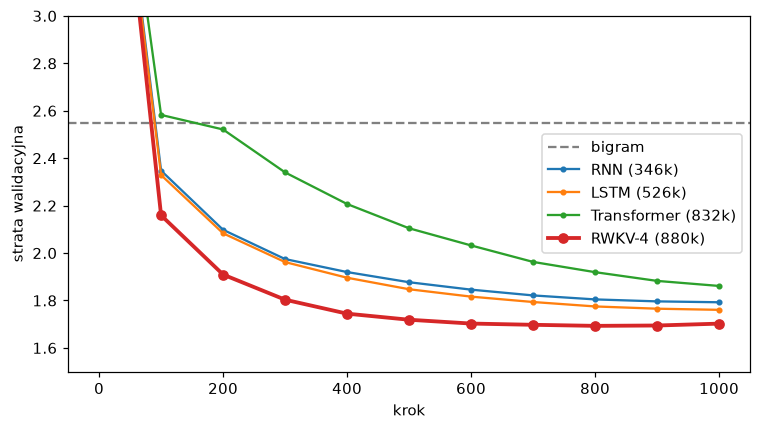

RWKV: 1.702, 265 ms/krok


In [20]:
fig, ax = plt.subplots(figsize=(8, 4.2))
bigram = load_results("00_bigram")
if bigram:
    ax.axhline(bigram["val_loss"][-1], color="gray", ls="--", label="bigram")
for name in ("01_rnn", "02_lstm", "03_transformer"):
    r = load_results(name)
    if r:
        ax.plot(r["eval_step"], r["val_loss"], "o-", ms=3, label=f"{r['name']} ({r['n_params'] / 1e3:.0f}k)")
ax.plot(hist["eval_step"], hist["val_loss"], "o-", lw=2.5, label=f"RWKV-4 ({hist['n_params'] / 1e3:.0f}k)")
ax.set_ylim(1.5, 3.0)
ax.set_xlabel("krok")
ax.set_ylabel("strata walidacyjna")
ax.legend()
plt.show()
print(f"RWKV: {hist['val_loss'][-1]:.3f}, {hist['sec_per_step'] * 1000:.0f} ms/krok")

RWKV od pierwszych kroków schodzi najszybciej. Dwa powody, oba opisane w sekcji 4.10:

- **token shift** daje każdej warstwie bezpośredni dostęp do poprzedniego znaku (dla modeli znakowych to bardzo
  pomaga, zauważył to autor już w RWKV-1),
- **inicjalizacja** (zerowe projekcje, spektrum zaników, mały embedding + LayerNorm) sprawia, że model nie traci
  czasu na "rozplątywanie" losowego startu. Porównaj z Transformerem, który stał w miejscu ~200 kroków.

Uczciwe zastrzeżenie: to bardzo mała skala. Paper pokazuje, że przy dużej skali RWKV jest **porównywalny**
z Transformerami tej samej wielkości, a nie wyraźnie lepszy.

### C3. Generowanie w trybie RNN

Prompt przetwarzamy w trybie GPT (równolegle), a potem generujemy znak po znaku w trybie RNN.
W przeciwieństwie do naszego GPT nie ma limitu długości: stan ma zawsze ten sam rozmiar.

In [21]:
@torch.no_grad()
def generate_rwkv(model, prompt, n_new, temperature=0.8, seed=0):
    model.eval()
    g = torch.Generator().manual_seed(seed)
    idx = torch.tensor([tok.encode(prompt)])
    logits, state = model(idx, return_state=True)
    logits = logits[:, -1]
    out = idx[0].tolist()
    for _ in range(n_new):
        nxt = sample_from_logits(logits, temperature, generator=g)
        out.append(nxt.item())
        logits, state = model.step(nxt[:, 0], state)
    model.train()
    return tok.decode(out)


sample = generate_rwkv(model, "Litwo! Ojczyzno moja! ", 600)
print(sample)
save_results("04_rwkv", {"name": "RWKV-4", **hist, "sample": sample})

Litwo! Ojczyzno moja! to za to piękną szczękę!
Ja, Sak — jak was różne wskąpano znacza;
Podoba, że każdy od śmiały się podniosło
I dawnego wyniknie w pokutu i Siwały,
Biegło głowę Tadeusza i na kąpinie
I oparł swe oszczuł łany tkami obrony,
Na dniech wyrazem nadzwyczajnymi kury;
Bez szlacheckiego pochwycił się życiu i pani,
Masz z rana albo pan jednego kierunku.

«U szlachciku! — ważna szlachta za odjecha,
Co to z nim cu nie mógł Sędziego przyszpilił.
Buchman, co się gościniec, spozierał się i plutu
Potrzeba się do waćpaństwu słuchać zrzedził.
I to będzie otwarcia nie wie, sam w córkowej szlachciców,
Obytcie ziemi 


PosixPath('/home/womackow/CODE_SPACE/agh/sem2/UMISI-sem2-NN-Arch/RWKV/results/04_rwkv.json')

---
# Część D: wydajność inferencji

### D1. Koszt jednego tokenu vs długość kontekstu

Ten sam rozmiar co Transformer w rozdziale 3 (`d = 256`, 4 warstwy). Dla każdej długości kontekstu
**naprawdę przetwarzamy** tyle tokenów (w trybie GPT, blokami), a potem mierzymy czas jednego kroku w trybie RNN.

In [22]:
gpt_bench = load_results("03_transformer_bench")
BENCH = gpt_bench or {"d_model": 256, "n_layer": 4, "contexts": [128, 512, 2048, 8192, 32768]}
set_seed(0)
bench_model = RWKV(tok.vocab_size, d=BENCH["d_model"], n_layer=BENCH["n_layer"]).eval()

rwkv_bench = {"context": [], "ms_per_token": [], "state_MB": [], "prefill_s": []}
with torch.no_grad():
    for ctx in BENCH["contexts"]:
        prompt = torch.randint(tok.vocab_size, (1, ctx))
        t0 = time.perf_counter()
        _, state = bench_model(prompt, return_state=True, chunk_len=64)
        prefill = time.perf_counter() - t0
        token = torch.tensor([0])
        gc.collect()
        ms = time_fn(lambda: bench_model.step(token, state), repeats=50, warmup=10) * 1000
        state_mb = 5 * BENCH["n_layer"] * BENCH["d_model"] * 4 / 2**20
        for key, val in zip(rwkv_bench, (ctx, ms, state_mb, prefill)):
            rwkv_bench[key].append(val)
        print(f"kontekst {ctx:6d}: {ms:5.2f} ms/token, stan {state_mb:.3f} MB  (wczytanie promptu w trybie GPT: {prefill:5.1f} s)")
save_results("04_rwkv_bench", {**{k: BENCH[k] for k in ("d_model", "n_layer", "contexts")}, **rwkv_bench})

kontekst    128:  0.88 ms/token, stan 0.020 MB  (wczytanie promptu w trybie GPT:   0.0 s)


kontekst    512:  0.86 ms/token, stan 0.020 MB  (wczytanie promptu w trybie GPT:   0.0 s)


kontekst   2048:  0.87 ms/token, stan 0.020 MB  (wczytanie promptu w trybie GPT:   0.2 s)


kontekst   8192:  0.86 ms/token, stan 0.020 MB  (wczytanie promptu w trybie GPT:   0.7 s)


kontekst  32768:  0.88 ms/token, stan 0.020 MB  (wczytanie promptu w trybie GPT:   3.3 s)


PosixPath('/home/womackow/CODE_SPACE/agh/sem2/UMISI-sem2-NN-Arch/RWKV/results/04_rwkv_bench.json')

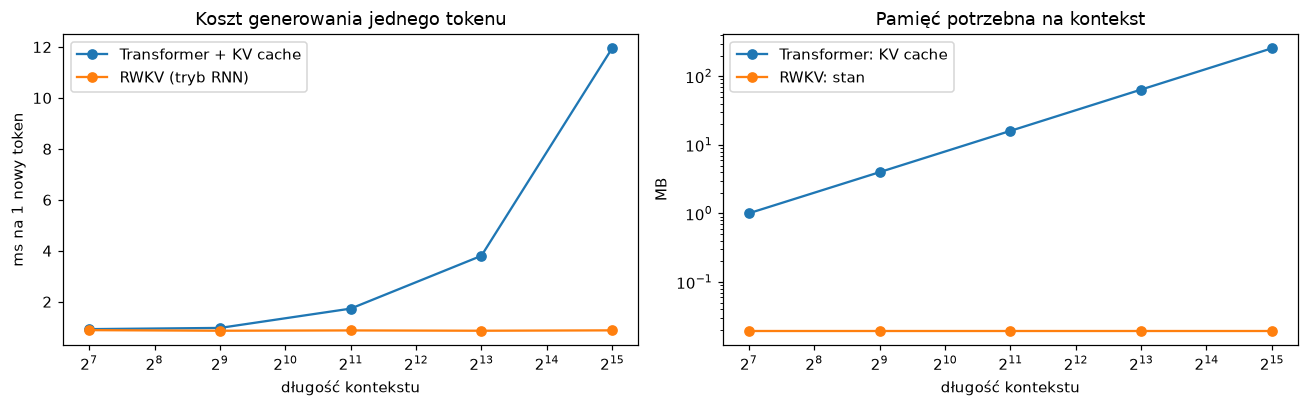

In [23]:
fig, axes = plt.subplots(1, 2, figsize=(12, 3.8))
if gpt_bench:
    axes[0].plot(gpt_bench["context"], gpt_bench["ms_per_token"], "o-", label="Transformer + KV cache")
    axes[1].plot(gpt_bench["context"], gpt_bench["cache_MB"], "o-", label="Transformer: KV cache")
axes[0].plot(rwkv_bench["context"], rwkv_bench["ms_per_token"], "o-", label="RWKV (tryb RNN)")
axes[1].plot(rwkv_bench["context"], rwkv_bench["state_MB"], "o-", label="RWKV: stan")
for ax in axes:
    ax.set_xscale("log", base=2)
    ax.set_xlabel("długość kontekstu")
    ax.legend()
axes[0].set_ylabel("ms na 1 nowy token")
axes[0].set_title("Koszt generowania jednego tokenu")
axes[1].set_yscale("log")
axes[1].set_ylabel("MB")
axes[1].set_title("Pamięć potrzebna na kontekst")
plt.tight_layout()
plt.show()

To jest obiecana "zajebista optymalizacja":

- koszt tokenu w RWKV **nie zależy od długości kontekstu**: 100. czy 30 000. token kosztuje tyle samo,
- pamięć na kontekst to **stałe 5 · L · d liczb** (tu kilkadziesiąt kB), zamiast setek MB KV cache,
- prompt można wczytać równolegle (tryb GPT), a dalej iść rekurencyjnie.

W prawdziwych rozmiarach (7B, kontekst 32k) to różnica między ~16 GB KV cache a ~3 MB stanu.

---
# Część E: czego nauczył się model?

### E1. Zaniki w kolejnych warstwach

Paper (Appendix I, Fig. 10) pokazuje posortowane $e^{-w}$ w każdej warstwie modelu 169M: w pierwszych warstwach
wiele kanałów zapomina natychmiast (operacje lokalne), w ostatnich część kanałów ma zanik bliski 1
(informacja niesiona przez cały kontekst). Sprawdźmy nasz mały model.

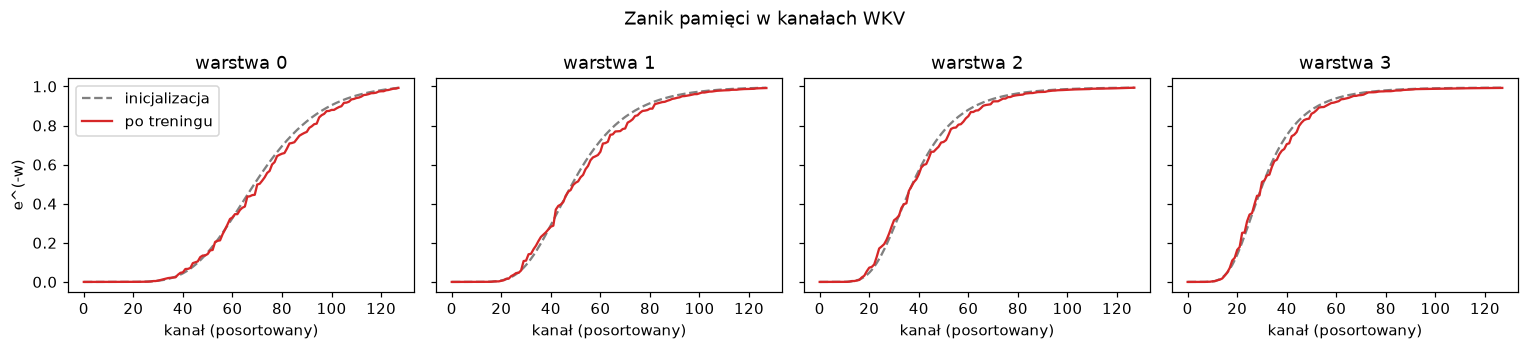

In [24]:
fig, axes = plt.subplots(1, len(model.blocks), figsize=(14, 3.2), sharey=True)
for layer, (ax, block) in enumerate(zip(axes, model.blocks)):
    learned = torch.exp(-torch.exp(block.att.time_decay.detach())).sort().values
    ax.plot(init_decay[layer].sort().values, "--", color="gray", label="inicjalizacja")
    ax.plot(learned, color="C3", label="po treningu")
    ax.set_title(f"warstwa {layer}")
    ax.set_xlabel("kanał (posortowany)")
axes[0].set_ylabel("e^(-w)")
axes[0].legend()
plt.suptitle("Zanik pamięci w kanałach WKV")
plt.tight_layout()
plt.show()

W naszym małym modelu i krótkim treningu zaniki prawie nie odeszły od inicjalizacji: "fancy init" od razu daje
sensowne spektrum od "zapominam natychmiast" ($e^{-w} \approx 0$) do "pamiętam długo" ($e^{-w} \approx 1$),
a model dopasował je tylko lekko. Widać za to wzór z paperu: im głębsza warstwa, tym więcej kanałów z długą pamięcią
(krzywa przesuwa się w lewo). Autorzy piszą wprost, że ten wzór jest częściowo wyuczony, a częściowo pochodzi
z inicjalizacji, bo przyspiesza ona trening.

### E2. "Uwaga" RWKV na prawdziwym tekście

Możemy wyciągnąć klucze $k$ z wytrenowanego modelu (hookiem na warstwie `key`) i narysować wagi
$\alpha_{t,i} = \operatorname{softmax}_i(k_i + \text{bias}_{t,i})$ dla wybranych kanałów:
tego z najszybszym i tego z najwolniejszym zanikiem, w pierwszej i ostatniej warstwie.

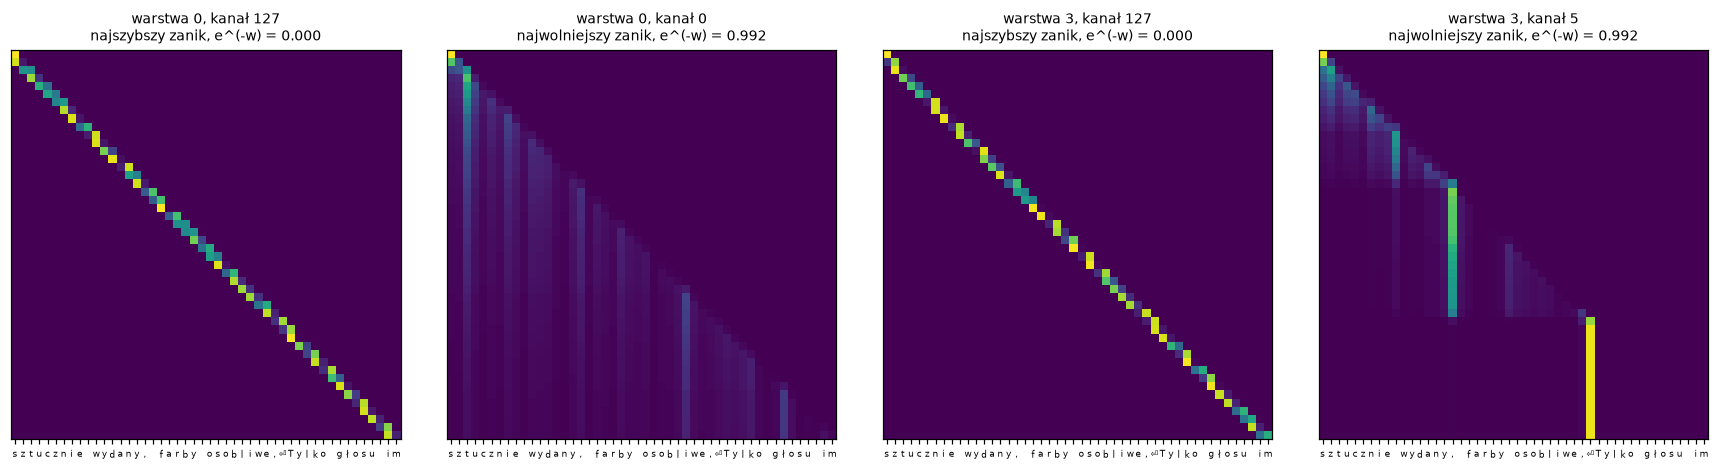

In [25]:
snippet = val_data[3000:3048]
captured = {}
hooks = [block.att.key.register_forward_hook(lambda m, i, o, layer=l: captured.__setitem__(layer, o.detach()))
         for l, block in enumerate(model.blocks)]
with torch.no_grad():
    model(snippet[None])
for h in hooks:
    h.remove()

T = len(snippet)
fig, axes = plt.subplots(1, 4, figsize=(16, 4))
panels = []
for layer in (0, len(model.blocks) - 1):
    att = model.blocks[layer].att
    w_layer = torch.exp(att.time_decay.detach())
    panels += [(layer, w_layer.argmax().item(), "najszybszy zanik"), (layer, w_layer.argmin().item(), "najwolniejszy zanik")]
for ax, (layer, ch, label) in zip(axes, panels):
    att = model.blocks[layer].att
    bias = decay_bias(torch.exp(att.time_decay.detach()), att.time_first.detach(), torch.arange(T), torch.arange(T))
    alpha = (captured[layer][0, :, ch][None, :] + bias[ch]).softmax(-1)
    ax.imshow(alpha, cmap="viridis", vmin=0, vmax=1)
    ax.set_title(f"warstwa {layer}, kanał {ch}\n{label}, e^(-w) = {math.exp(-math.exp(att.time_decay[ch].item())):.3f}", fontsize=9)
    ax.set_xticks(range(T), list(tok.decode(snippet).replace("\n", "⏎")), fontsize=6)
    ax.set_yticks([])
plt.tight_layout()
plt.show()

Kanały z szybkim zanikiem patrzą praktycznie tylko na bieżący token. Kanały z wolnym zanikiem uśredniają
dużą część historii, a "jasne" kolumny to tokeny z dużym $k$, które model uznał za warte zapamiętania.
Kształt wzoru jest zawsze ten sam (zanik), ale **które** tokeny są ważne, zależy od treści.

---
# Część F: zadanie pamięciowe

In [26]:
MEMORY_LENGTHS = [5, 10, 20, 40, 80, 160]
memory = run_memory_experiment(lambda: RWKV(MEMORY_VOCAB, d=64, n_layer=2), MEMORY_LENGTHS, name="RWKV-4")
save_results("04_rwkv_memory", memory)

L =    5: trafność 100% / 100%   kroki treningu:   62 /   61   (1 s)


L =   10: trafność 100% / 100%   kroki treningu:   68 /   69   (2 s)


L =   20: trafność 100% / 100%   kroki treningu:   74 /   75   (4 s)


L =   40: trafność 100% / 100%   kroki treningu:   78 /   83   (7 s)


L =   80: trafność 100% / 100%   kroki treningu:   89 /   88   (14 s)


L =  160: trafność 100% / 100%   kroki treningu:  100 /  108   (35 s)


PosixPath('/home/womackow/CODE_SPACE/agh/sem2/UMISI-sem2-NN-Arch/RWKV/results/04_rwkv_memory.json')

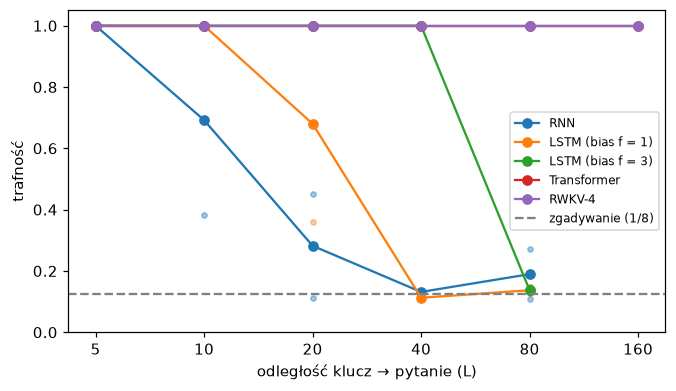

In [27]:
plot_memory([load_results(n) for n in ("01_rnn_memory", "02_lstm_memory", "02_lstm_memory_fb3",
                                       "03_transformer_memory")] + [memory])
plt.show()

RWKV radzi sobie z dalekimi zależnościami w tym zadaniu, bo wystarczy jeden kanał z $e^{-w} \approx 1$ i duże
$k$ dla klucza: średnia ważona w WKV zostanie zdominowana przez klucz niezależnie od odległości (token shift
pozwala rozpoznać, że to pierwszy token, bo jego "poprzednik" to zero). Gradient płynie przez znormalizowaną
średnią, a nie przez iloczyn jakobianów, więc nie znika.

To zadanie wymaga zapamiętania **jednej** liczby. Gdyby trzeba było zapamiętać setki par klucz–wartość, stały
stan RWKV-4 (jedna liczba "średniej" na kanał) zacząłby przegrywać z Transformerem (rozdział 3.7, sekcja 4.12).

---
## Podsumowanie

- **WKV** to średnia ważona przeszłych wartości z wagami $e^{k_i}$ i zanikiem $e^{-w}$ na kanał. Można go liczyć
  rekurencyjnie (RNN), równolegle (jak attention) albo blokami, z identycznym wynikiem.
- Wszystkie mnożenia macierzy w RWKV zależą tylko od wejścia warstwy (bieżący i poprzedni token), więc w treningu
  liczą się równolegle jak w Transformerze. Rekurencyjna jest tylko tania, liniowa część element po elemencie.
- **Stabilność**: śledzenie wykładnika w stanie WKV (log-sum-exp), parametryzacja $e^{-e^{x}}$, zerowa
  i "fancy" inicjalizacja, mały embedding + LayerNorm, Pre-LN, `L2Wrap`.
- **Inferencja**: stały koszt tokenu i stała, malutka pamięć, w przeciwieństwie do KV cache.
- **Ograniczenie**: stały stan i z góry zadany kształt "uwagi" (zanik). To właśnie poprawiają RWKV-5/6/7.

**Dalej:** [`05_podsumowanie.md`](05_podsumowanie.md) → [`05_porownanie.ipynb`](05_porownanie.ipynb)